# MAP: Charting Student Math Misunderstandings — Suffix Classification Pipeline

## Approach: Suffix Classification with Qwen2.5-3B + QLoRA

Instead of mapping inputs to 65 abstract class indices (DeBERTa approach),
this pipeline uses **suffix classification** inspired by the 1st-place solution:

1. Build a **prefix** (context) containing the question, choices, correct answer, student answer, and explanation
2. Build **candidate suffixes** — one per possible label for that question (6–12 candidates)
3. Concatenate `prefix + each suffix` and extract last-token hidden states
4. Score each candidate with `nn.Linear(hidden_size, 1)` → cross-entropy over candidates

The model **reads the misconception names** as input text, so it can reason about
whether a misconception matches the student's error — even for unseen questions.

### Architecture
```
┌──────────────────────────────────────────────────────────────────────┐
│                     SUFFIX CLASSIFICATION                            │
├──────────────────────────────────────────────────────────────────────┤
│                                                                      │
│  1. Data: 36,696 samples, 15 questions, 65 labels                   │
│  2. Model: Qwen2.5-3B-Instruct + QLoRA (4-bit)                     │
│  3. Input: prefix + candidate_suffix → last-token features          │
│  4. Output: logit per candidate → CE loss → predict best match      │
│  5. Training: 1 epoch, 2 seeds, StratifiedGroupKFold               │
│  6. Explainable AI: LLM Knowledge Base + Teacher Feedback           │
│                                                                      │
└──────────────────────────────────────────────────────────────────────┘
```

### Key References
| # | Technique | Reference |
|---|-----------|----------|
| 1 | **Qwen 2.5** | Qwen Team (2024). *Qwen2.5 Technical Report.* [arXiv:2412.15115](https://arxiv.org/abs/2412.15115) |
| 2 | **QLoRA** | Dettmers et al. (2023). *QLoRA: Efficient Finetuning of Quantized LLMs.* NeurIPS 2023. [arXiv:2305.14314](https://arxiv.org/abs/2305.14314) |
| 3 | **Suffix Classification** | tascj (2025). *1st Place Solution — MAP Competition.* Kaggle Writeup. |
| 4 | **Temperature Scaling** | Guo et al. (2017). *On Calibration of Modern Neural Networks.* ICML 2017. |
| 5 | **Multi-Seed Ensemble** | Lakshminarayanan et al. (2017). *Deep Ensembles.* NeurIPS 2017. |

## Cell 1 — Environment Setup

In [1]:
import sys, subprocess

def pip_install(cmd):
    subprocess.check_call([sys.executable, "-m", "pip"] + cmd.split())

# Kaggle installs
pip_install("install -U -q pip setuptools wheel")
pip_install("install -q -U transformers==4.45.2 datasets==2.21.0 accelerate==0.34.2 sentencepiece")
pip_install("install -q -U bitsandbytes peft")

# ============================================================
# IMPORTS
# ============================================================
import os
import gc
import json
import re
import warnings
from pathlib import Path
from collections import Counter
import time as _time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset as TorchDataset, DataLoader

from transformers import (
    AutoTokenizer, AutoModelForCausalLM,
    AutoModelForSeq2SeqLM,
    BitsAndBytesConfig,
    get_cosine_schedule_with_warmup,
    set_seed,
)
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    free, total = torch.cuda.mem_get_info()
    print(f"VRAM: {free/1e9:.1f} GB free / {total/1e9:.1f} GB total")
print("All imports successful.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 71.5 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.31.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.6.1 which is incompatible.


Device: cuda
GPU: NVIDIA H100 80GB HBM3
VRAM: 84.5 GB free / 85.0 GB total
All imports successful.


## Cell 2 — Configuration

In [2]:
# ============================================================
# CONFIGURATION
# ============================================================

QUICK_RUN = False

# --- Paths ---
# Try competition path first, then custom dataset path
import os as _os
TRAIN_PATH = (
    "/kaggle/input/map-charting-student-math-misunderstandings/train.csv"
    if _os.path.exists("/kaggle/input/map-charting-student-math-misunderstandings/train.csv")
    else "/kaggle/input/datasets/mkhanshovon43/map-ds/DS/train.csv"
)
TEST_PATH = (
    "/kaggle/input/map-charting-student-math-misunderstandings/test.csv"
    if _os.path.exists("/kaggle/input/map-charting-student-math-misunderstandings/test.csv")
    else "/kaggle/input/datasets/mkhanshovon43/map-ds/DS/test.csv"
)
WORKDIR    = Path("./")

# --- Model ---
MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"

# --- Explainer LLM (reuses same model for KB, then unloaded) ---
EXPLAINER_MODEL          = MODEL_NAME  # reuse Qwen for KB generation
EXPLAINER_FALLBACK_MODEL = "google/flan-t5-large"

# --- Training ---
if QUICK_RUN:
    N_FOLDS    = 3
    SEEDS      = [42]
    EPOCHS     = 1
else:
    N_FOLDS    = 5
    SEEDS      = [42]
    EPOCHS     = 1    # 1 epoch is sufficient for fine-tuned LLMs (per 1st place)

BATCH_SIZE     = 2    # H100 has plenty of VRAM
GRAD_ACCUM     = 8    # effective batch = 16
LR             = 1e-4 # LoRA learning rate (higher than full finetune)
MAX_LEN        = 512  # prefix + suffix combined length
WEIGHT_DECAY   = 0.01
WARMUP_RATIO   = 0.05
MAX_GRAD_NORM  = 1.0

# --- Candidate subsampling (speed up training) ---
MAX_TRAIN_CANDIDATES = 4   # subsample negatives during training (correct + 3 random)

# --- Time management ---
TIME_LIMIT_HOURS = 11.0    # H100 training notebook — generous limit
PIPELINE_START_TIME = _time.time()

# --- QLoRA ---
LORA_R         = 32
LORA_ALPHA     = 64
LORA_DROPOUT   = 0.05
LORA_TARGETS   = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]

# --- Post-processing ---
USE_TEMPERATURE_SCALING = True
TEMPERATURE = 1.0

# --- Model saving ---
SAVE_FOLD_MODELS = True
MODEL_SAVE_DIR   = WORKDIR / "fold_models"

# --- Explainability ---
USE_LLM_EXPLAINER  = True
USE_LLM_VERIFIER   = True
KB_BUILD_TOP_N     = 50 if QUICK_RUN else 150
KB_EXAMPLES_PER_MISCON = 4 if QUICK_RUN else 5
KB_PATH = WORKDIR / "misconception_kb.json"

print("=" * 60)
print(f"  MODE: {'QUICK RUN' if QUICK_RUN else 'FULL RUN'}")
print("=" * 60)
print(f"  Model: {MODEL_NAME}")
print(f"  Folds: {N_FOLDS} | Seeds: {SEEDS} | Epochs: {EPOCHS}")
print(f"  Effective batch: {BATCH_SIZE * GRAD_ACCUM}")
print(f"  LoRA r={LORA_R}, alpha={LORA_ALPHA}")
print(f"  Max seq length: {MAX_LEN}")
print(f"  Max train candidates: {MAX_TRAIN_CANDIDATES}")
print(f"  Time limit: {TIME_LIMIT_HOURS}h")


  MODE: FULL RUN
  Model: Qwen/Qwen2.5-3B-Instruct
  Folds: 5 | Seeds: [42] | Epochs: 1
  Effective batch: 16
  LoRA r=32, alpha=64
  Max seq length: 512
  Max train candidates: 4
  Time limit: 11.0h


## Cell 3 — Data Loading & EDA

Dataset shape: (36696, 7)
Columns: ['row_id', 'QuestionId', 'QuestionText', 'MC_Answer', 'StudentExplanation', 'Category', 'Misconception']
Dropped 736 duplicates → 35960 samples

Unique Questions: 15
Total labels: 65
Candidates per question:
  Q31772: 8 candidates
  Q31774: 10 candidates
  Q31777: 7 candidates
  Q31778: 9 candidates
  Q32829: 8 candidates
  Q32833: 9 candidates
  Q32835: 11 candidates
  Q33471: 7 candidates
  Q33472: 10 candidates
  Q33474: 8 candidates
  Q76870: 8 candidates
  Q89443: 8 candidates
  Q91695: 8 candidates
  Q104665: 8 candidates
  Q109465: 6 candidates


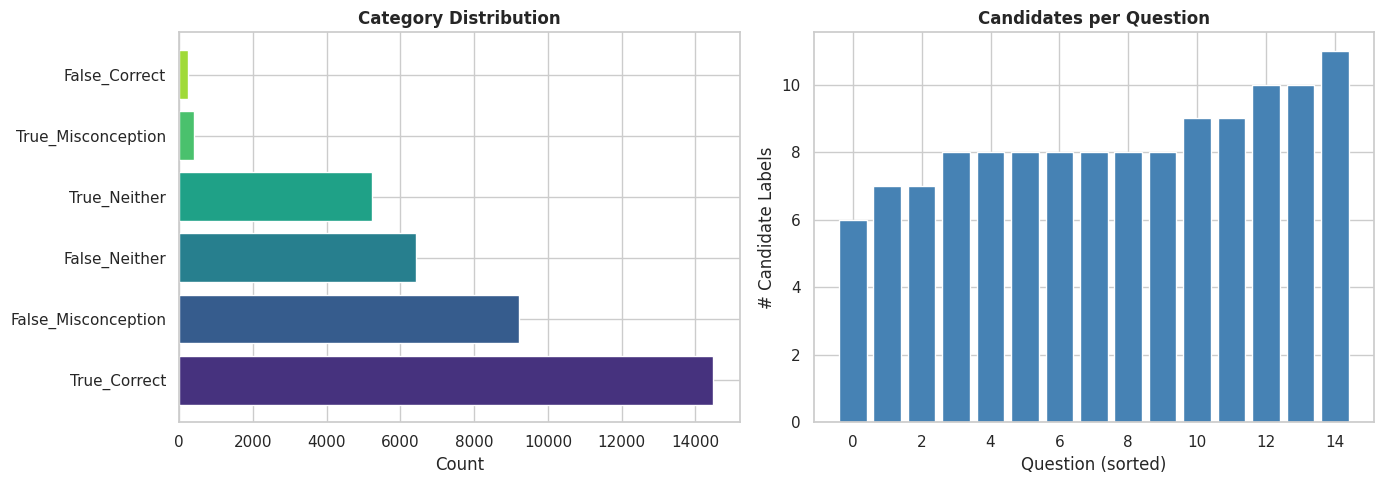

In [3]:
# ============================================================
# DATA LOADING & EDA
# ============================================================

train_df = pd.read_csv(TRAIN_PATH)
print(f"Dataset shape: {train_df.shape}")
print(f"Columns: {train_df.columns.tolist()}")

# Fill NaN
train_df["StudentExplanation"] = train_df["StudentExplanation"].fillna("")
train_df["QuestionText"]       = train_df["QuestionText"].fillna("")
train_df["MC_Answer"]          = train_df["MC_Answer"].fillna("")
train_df["Misconception"]      = train_df["Misconception"].fillna("NA")

# Create combined label
train_df["label_str"] = train_df["Category"] + ":" + train_df["Misconception"]

# Drop exact duplicates (same as 1st place: 35,960 → ~36,000 samples)
n_before = len(train_df)
train_df = train_df.drop_duplicates(
    subset=["QuestionId", "MC_Answer", "StudentExplanation", "Category", "Misconception"]
).reset_index(drop=True)
print(f"Dropped {n_before - len(train_df)} duplicates → {len(train_df)} samples")

# --- Build per-question candidate label sets ---
question_candidates = {}
for qid in train_df["QuestionId"].unique():
    candidates = sorted(train_df[train_df["QuestionId"] == qid]["label_str"].unique().tolist())
    question_candidates[qid] = candidates

# Global label set (for OOF scoring)
all_labels = sorted(train_df["label_str"].unique().tolist())
lab2id_global = {c: i for i, c in enumerate(all_labels)}
id2lab_global = {i: c for c, i in lab2id_global.items()}
num_labels_global = len(all_labels)

# Infer correct answer per question
def build_correct_by_q(df):
    correct_mask = df["Category"].str.startswith("True", na=False)
    tmp = df.loc[correct_mask, ["QuestionId", "MC_Answer"]].dropna()
    if len(tmp) == 0:
        return {}
    return tmp.groupby("QuestionId")["MC_Answer"].agg(
        lambda s: s.value_counts().index[0]
    ).to_dict()

correct_by_q_full = build_correct_by_q(train_df)

print(f"\nUnique Questions: {train_df['QuestionId'].nunique()}")
print(f"Total labels: {num_labels_global}")
print(f"Candidates per question:")
for qid, cands in question_candidates.items():
    print(f"  Q{qid}: {len(cands)} candidates")

# --- EDA plots ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cat_counts = train_df["Category"].value_counts()
ax = axes[0]
ax.barh(cat_counts.index, cat_counts.values, color=sns.color_palette("viridis", len(cat_counts)))
ax.set_title("Category Distribution", fontweight="bold")
ax.set_xlabel("Count")

n_cands = [len(v) for v in question_candidates.values()]
ax = axes[1]
ax.bar(range(len(n_cands)), sorted(n_cands), color="steelblue")
ax.set_title("Candidates per Question", fontweight="bold")
ax.set_xlabel("Question (sorted)")
ax.set_ylabel("# Candidate Labels")

plt.tight_layout()
plt.show()

## Cell 4 — Suffix Classification: Prompt Construction

The key innovation: each sample is converted to **N candidate inputs** (prefix + suffix_i).
The model scores each candidate and learns to pick the correct one via cross-entropy.

In [4]:
# ============================================================
# SUFFIX CLASSIFICATION — PROMPT CONSTRUCTION
# ============================================================

def build_prefix(row, correct_by_q):
    """
    Build the shared context prefix for a sample.
    Includes question, choices, correct answer, student answer, explanation.
    """
    qtext   = str(row["QuestionText"])
    ans     = str(row["MC_Answer"])
    expl    = str(row["StudentExplanation"])
    qid     = row["QuestionId"]
    correct = str(correct_by_q.get(qid, "unknown"))
    
    # Determine correctness
    is_correct = "Yes" if ans == correct else "No" if correct != "unknown" else "Unknown"
    
    prefix = (
        f"<|im_start|>user\n"
        f"**Question:** {qtext}\n"
        f"**Correct Answer:** {correct}\n"
        f"**Student Answer:** {ans}\n"
        f"**Is Correct:** {is_correct}\n"
        f"**Student Explanation:** {expl}\n"
        f"\nClassify this student response into one of the candidate categories below.\n"
        f"<|im_end|>\n"
        f"<|im_start|>assistant\n"
    )
    return prefix


def build_suffix(label_str):
    """
    Build a candidate suffix from a label string.
    E.g., 'False_Misconception:WNB' → 'False_Misconception:WNB<|im_end|>'
    """
    return f"{label_str}<|im_end|>"


# Demo
demo_row = train_df.iloc[0]
demo_prefix = build_prefix(demo_row, correct_by_q_full)
demo_qid = demo_row["QuestionId"]
demo_candidates = question_candidates[demo_qid]

print("=" * 70)
print("SAMPLE PREFIX:")
print("=" * 70)
print(demo_prefix[:500])
print()
print(f"CANDIDATE SUFFIXES ({len(demo_candidates)}):")
for c in demo_candidates:
    print(f"  → {build_suffix(c)}")
print(f"\nTrue label: {demo_row['label_str']}")
print(f"True label index in candidates: {demo_candidates.index(demo_row['label_str'])}")

SAMPLE PREFIX:
<|im_start|>user
**Question:** What fraction of the shape is not shaded? Give your answer in its simplest form. [Image: A triangle split into 9 equal smaller triangles. 6 of them are shaded.]
**Correct Answer:** \( \frac{1}{3} \)
**Student Answer:** \( \frac{1}{3} \)
**Is Correct:** Yes
**Student Explanation:** 0ne third is equal to tree nineth

Classify this student response into one of the candidate categories below.
<|im_end|>
<|im_start|>assistant


CANDIDATE SUFFIXES (8):
  → False_Correct:NA<|im_end|>
  → False_Misconception:Incomplete<|im_end|>
  → False_Misconception:WNB<|im_end|>
  → False_Neither:NA<|im_end|>
  → True_Correct:NA<|im_end|>
  → True_Misconception:Incomplete<|im_end|>
  → True_Misconception:WNB<|im_end|>
  → True_Neither:NA<|im_end|>

True label: True_Correct:NA
True label index in candidates: 4


## Cell 5 — Dataset & Collator for Suffix Classification

In [5]:
# ============================================================
# DATASET FOR SUFFIX CLASSIFICATION
# ============================================================

class SuffixClassificationDataset(TorchDataset):
    """
    Each sample returns:
      - input_ids/attention_mask for ALL candidates (prefix+suffix for each)
      - label: index of the correct candidate
      - n_candidates: number of candidates for this question
    """
    def __init__(self, df, tokenizer, question_candidates, correct_by_q, max_len=512, training=False):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.question_candidates = question_candidates
        self.correct_by_q = correct_by_q
        self.max_len = max_len
        self.training = training
    
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        qid = row["QuestionId"]
        true_label = row["label_str"]
        candidates = self.question_candidates[qid]

        # Subsample candidates during training for speed
        if self.training and len(candidates) > MAX_TRAIN_CANDIDATES:
            import random
            # Always keep the correct label, randomly pick rest
            others = [c for c in candidates if c != true_label]
            random.shuffle(others)
            candidates = [true_label] + others[:MAX_TRAIN_CANDIDATES - 1]
            candidates.sort()  # deterministic ordering by name
        
        prefix = build_prefix(row, self.correct_by_q)
        
        all_input_ids = []
        all_attention_mask = []
        
        for cand in candidates:
            full_text = prefix + build_suffix(cand)
            enc = self.tokenizer(
                full_text,
                truncation=True,
                max_length=self.max_len,
                padding=False,
                return_tensors=None,
            )
            all_input_ids.append(enc["input_ids"])
            all_attention_mask.append(enc["attention_mask"])
        
        label_idx = candidates.index(true_label) if true_label in candidates else 0
        
        return {
            "input_ids_list": all_input_ids,
            "attention_mask_list": all_attention_mask,
            "label": label_idx,
            "n_candidates": len(candidates),
            "qid": qid,
            "true_label": true_label,
        }


def suffix_collate_fn(batch):
    """
    Collate: flatten all candidates across the batch, pad, and track
    which candidates belong to which sample.
    """
    all_input_ids = []
    all_attention_mask = []
    labels = []
    offsets = [0]  # cumulative offset for each sample's candidates
    n_candidates_list = []
    qids = []
    true_labels = []
    
    for item in batch:
        n_cand = item["n_candidates"]
        n_candidates_list.append(n_cand)
        labels.append(item["label"])
        qids.append(item["qid"])
        true_labels.append(item["true_label"])
        
        for i in range(n_cand):
            all_input_ids.append(torch.tensor(item["input_ids_list"][i], dtype=torch.long))
            all_attention_mask.append(torch.tensor(item["attention_mask_list"][i], dtype=torch.long))
        
        offsets.append(offsets[-1] + n_cand)
    
    # Left-pad all sequences to the same length (required for causal LMs)
    max_len = max(ids.size(0) for ids in all_input_ids)
    
    padded_input_ids = torch.zeros(len(all_input_ids), max_len, dtype=torch.long)
    padded_attention_mask = torch.zeros(len(all_input_ids), max_len, dtype=torch.long)
    
    for i, (ids, mask) in enumerate(zip(all_input_ids, all_attention_mask)):
        pad_len = max_len - ids.size(0)
        padded_input_ids[i, pad_len:] = ids
        padded_attention_mask[i, pad_len:] = mask
    
    return {
        "input_ids": padded_input_ids,          # [total_candidates, max_len]
        "attention_mask": padded_attention_mask,  # [total_candidates, max_len]
        "labels": torch.tensor(labels, dtype=torch.long),  # [batch_size]
        "offsets": offsets,                       # list of len batch_size+1
        "n_candidates": n_candidates_list,        # list of len batch_size
        "qids": qids,
        "true_labels": true_labels,
    }

print("Dataset and collator defined.")

Dataset and collator defined.


## Cell 6 — Model: Qwen2.5-3B with QLoRA + Scoring Head

In [6]:
# ============================================================
# MODEL: SUFFIX CLASSIFIER
# ============================================================

class SuffixClassifier(nn.Module):
    """
    Wraps a causal LM and adds a linear scoring head on last-token features.
    
    For each candidate (prefix+suffix), we:
    1. Run through the LM to get hidden states
    2. Extract the last non-padding token's hidden state
    3. Score with nn.Linear(hidden_size, 1) → scalar logit
    4. Gather logits per-sample and apply cross-entropy
    """
    def __init__(self, base_model, hidden_size):
        super().__init__()
        self.base_model = base_model
        self.score_head = nn.Linear(hidden_size, 1, bias=False)
        # Initialize score head with small weights
        nn.init.normal_(self.score_head.weight, std=0.02)
    
    def forward(self, input_ids, attention_mask):
        """
        Args:
            input_ids: [N_total_candidates, seq_len]
            attention_mask: [N_total_candidates, seq_len]
        Returns:
            logits: [N_total_candidates, 1] — one score per candidate
        """
        outputs = self.base_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_hidden_states=True,
        )
        # Get last hidden state
        hidden = outputs.hidden_states[-1]  # [N, seq_len, hidden_size]
        
        # Extract last non-padding token's hidden state
        # Find the last position where attention_mask == 1
        # With left-padding, last real token is always at position -1

        last_hidden = hidden[:, -1]  # [N, hidden_size]
        
        # Always compute score in fp32 to avoid fp16 overflow (2048-dim dot product)
        logits = self.score_head(last_hidden.float())  # [N, 1]
        return logits.squeeze(-1)  # [N]


def compute_suffix_loss(logits_flat, labels, offsets, n_candidates):
    """
    Compute cross-entropy loss for suffix classification.
    
    logits_flat: [total_candidates] — all candidate scores flattened
    labels: [batch_size] — index of correct candidate per sample
    offsets: list of cumulative offsets
    n_candidates: list of candidate counts per sample
    """
    batch_size = len(labels)
    total_loss = 0.0
    
    for i in range(batch_size):
        start = offsets[i]
        end = offsets[i + 1]
        sample_logits = logits_flat[start:end]  # [n_cand_i]
        target = labels[i].unsqueeze(0)  # [1]
        loss = F.cross_entropy(sample_logits.unsqueeze(0), target)
        total_loss += loss
    
    return total_loss / batch_size


def load_qwen_qlora():
    """Load Qwen with QLoRA with 4-bit quantization and LoRA."""
    print(f"Loading {MODEL_NAME} with 4-bit quantization...")
    
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_use_double_quant=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
    )
    
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
        tokenizer.pad_token_id = tokenizer.eos_token_id
    tokenizer.padding_side = "left"  # left-pad for causal LM
    
    base_model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        quantization_config=bnb_config,
        device_map="auto",
        torch_dtype=torch.float16,
        attn_implementation="eager",
    )
    base_model = prepare_model_for_kbit_training(base_model)
    
    # Apply LoRA
    lora_config = LoraConfig(
        r=LORA_R,
        lora_alpha=LORA_ALPHA,
        target_modules=LORA_TARGETS,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        task_type=TaskType.CAUSAL_LM,
    )
    base_model = get_peft_model(base_model, lora_config)
    base_model.print_trainable_parameters()
    
    hidden_size = base_model.config.hidden_size
    model = SuffixClassifier(base_model, hidden_size)
    # Move score_head to device but keep fp32 to avoid overflow
    model.score_head = model.score_head.to(device=base_model.device, dtype=torch.float32)
    
    print(f"Hidden size: {hidden_size}")
    print(f"Model loaded successfully.")
    
    return model, tokenizer

print("Model architecture defined.")

Model architecture defined.


## Cell 7 — Training Utilities

In [7]:
# ============================================================
# TRAINING UTILITIES
# ============================================================

def map_at_3_suffix(true_labels, pred_logits_per_sample, question_candidates_map, qids):
    """
    Compute MAP@3 for suffix classification.
    
    true_labels: list of true label strings
    pred_logits_per_sample: list of np arrays, each [n_candidates_i]
    question_candidates_map: dict qid → list of candidate label strings
    qids: list of question IDs
    """
    total_ap = 0.0
    n = len(true_labels)
    
    for i in range(n):
        qid = qids[i]
        candidates = question_candidates_map[qid]
        logits = pred_logits_per_sample[i]
        true_label = true_labels[i]
        
        # Get top-3 indices by score
        top3_idx = np.argsort(logits)[::-1][:3]
        top3_labels = [candidates[j] for j in top3_idx]
        
        # AP@3
        ap = 0.0
        for rank, pred in enumerate(top3_labels, 1):
            if pred == true_label:
                ap = 1.0 / rank
                break
        total_ap += ap
    
    return total_ap / max(n, 1)


def get_top3_labels(logits, candidates):
    """Get top-3 label strings from logits and candidate list."""
    top3_idx = np.argsort(logits)[::-1][:3]
    return [candidates[j] for j in top3_idx]


def learn_temperature_suffix(all_logits_per_sample, true_labels, question_candidates_map, qids):
    """
    Learn optimal temperature by grid search on MAP@3.
    """
    best_temp = 1.0
    best_map3 = 0.0
    
    for temp in np.arange(0.5, 3.0, 0.05):
        scaled = [logits / temp for logits in all_logits_per_sample]
        m = map_at_3_suffix(true_labels, scaled, question_candidates_map, qids)
        if m > best_map3:
            best_map3 = m
            best_temp = temp
    
    print(f"Learned temperature: {best_temp:.2f} → MAP@3: {best_map3:.6f}")
    return best_temp

print("Training utilities defined.")

Training utilities defined.


## Cell 8 — Training Loop: Suffix Classification with QLoRA

In [8]:
# ============================================================
# TRAINING LOOP
# ============================================================

tokenizer_global = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
if tokenizer_global.pad_token is None:
    tokenizer_global.pad_token = tokenizer_global.eos_token
    tokenizer_global.pad_token_id = tokenizer_global.eos_token_id
tokenizer_global.padding_side = "left"

groups = train_df["QuestionId"].values
gkf = GroupKFold(n_splits=N_FOLDS)

# Store OOF predictions
oof_logits_per_sample = [None] * len(train_df)  # each entry: np array [n_candidates]
oof_true_labels = train_df["label_str"].tolist()
oof_qids = train_df["QuestionId"].tolist()
fold_scores = []
saved_model_paths = []

if SAVE_FOLD_MODELS:
    MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

TRAINING_START_TIME = _time.time()

print(f"Training: {len(SEEDS)} seeds x {N_FOLDS} folds x {EPOCHS} epochs")
print(f"Model: {MODEL_NAME} + QLoRA (r={LORA_R})")
print("=" * 70)

for seed_idx, seed in enumerate(SEEDS):
    set_seed(seed)
    print(f"\n{'='*70}")
    print(f"  SEED {seed} ({seed_idx+1}/{len(SEEDS)})")
    print(f"{'='*70}")
    
    for fold, (tr_idx, va_idx) in enumerate(gkf.split(
            np.zeros(len(train_df)), train_df["label_str"].values, groups), start=1):
        
        # ---- TIME GUARD ----
        elapsed_total = (_time.time() - PIPELINE_START_TIME) / 3600
        remaining = TIME_LIMIT_HOURS - elapsed_total
        est_fold_hours = 1.5  # H100 is fast
        if remaining < est_fold_hours + 1.0:  # need 1h buffer for KB+inference
            print(f"    ⚠ Skipping fold {fold} — only {remaining:.1f}h remaining")
            continue

        fold_start = _time.time()
        tr_df = train_df.iloc[tr_idx]
        va_df = train_df.iloc[va_idx]
        
        print(f"\n--- Seed {seed} | Fold {fold}/{N_FOLDS} | "
              f"Train: {len(tr_df)} | Val: {len(va_df)} ---")
        
        # Build datasets
        train_dataset = SuffixClassificationDataset(
            tr_df, tokenizer_global, question_candidates, correct_by_q_full, MAX_LEN, training=True
        )
        val_dataset = SuffixClassificationDataset(
            va_df, tokenizer_global, question_candidates, correct_by_q_full, MAX_LEN
        )
        
        train_loader = DataLoader(
            train_dataset, batch_size=BATCH_SIZE, shuffle=True,
            collate_fn=suffix_collate_fn, num_workers=0,
        )
        val_loader = DataLoader(
            val_dataset, batch_size=BATCH_SIZE * 2, shuffle=False,
            collate_fn=suffix_collate_fn, num_workers=0,
        )
        
        # Load fresh model for this fold
        model, _ = load_qwen_qlora()
        model.base_model.gradient_checkpointing_enable()
        
        # Optimizer: LoRA params + score_head
        trainable_params = [
            {"params": [p for n, p in model.base_model.named_parameters() if p.requires_grad],
             "lr": LR},
            {"params": model.score_head.parameters(), "lr": LR * 10},  # higher LR for head
        ]
        optimizer = torch.optim.AdamW(trainable_params, lr=LR, weight_decay=WEIGHT_DECAY)
        
        num_steps = int(len(train_loader) / GRAD_ACCUM * EPOCHS)
        num_warmup = int(num_steps * WARMUP_RATIO)
        scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup, num_steps)
        
        print(f"    Steps: {num_steps} | Warmup: {num_warmup}")
        
        # ===================== TRAINING =====================
        model.train()
        optimizer.zero_grad()
        global_step = 0
        
        for epoch in range(EPOCHS):
            epoch_loss = 0.0
            epoch_correct = 0
            epoch_total = 0
            nan_count = 0
            valid_loss_steps = 0
            
            for step, batch in enumerate(train_loader):
                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)
                labels = batch["labels"].to(device)
                offsets = batch["offsets"]
                n_cands = batch["n_candidates"]
                
                # Forward pass — no autocast needed, model already fp16 via BitsAndBytes
                logits_flat = model(input_ids, attention_mask)  # [total_cands]
                # Compute loss in float32 to avoid overflow
                loss = compute_suffix_loss(logits_flat.float(), labels, offsets, n_cands)
                
                # NaN / Inf guard — skip bad batches to prevent gradient contamination
                if torch.isnan(loss) or torch.isinf(loss):
                    nan_count += 1
                    if nan_count <= 5:
                        print(f"      [WARN] NaN/Inf loss at step {step}, "
                              f"logits range=[{logits_flat.min().item():.4f}, {logits_flat.max().item():.4f}], "
                              f"n_cands={n_cands}, labels={labels.tolist()}")
                    optimizer.zero_grad()  # discard accumulated NaN grads
                    # Still track accuracy
                    with torch.no_grad():
                        for i in range(len(n_cands)):
                            start = offsets[i]
                            end = offsets[i + 1]
                            pred = logits_flat[start:end].argmax().item()
                            if pred == labels[i].item():
                                epoch_correct += 1
                            epoch_total += 1
                    continue
                
                # Debug for first 3 steps
                if step < 3:
                    print(f"      [DEBUG] Step {step}: loss={loss.item():.6f}, "
                          f"logits=[{logits_flat.min().item():.4f}, {logits_flat.max().item():.4f}]")
                
                loss = loss / GRAD_ACCUM
                loss.backward()
                epoch_loss += loss.item() * GRAD_ACCUM
                valid_loss_steps += 1
                
                # Track accuracy
                with torch.no_grad():
                    for i in range(len(n_cands)):
                        start = offsets[i]
                        end = offsets[i + 1]
                        pred = logits_flat[start:end].argmax().item()
                        if pred == labels[i].item():
                            epoch_correct += 1
                        epoch_total += 1
                
                if (step + 1) % GRAD_ACCUM == 0:
                    torch.nn.utils.clip_grad_norm_(
                        [p for p in model.parameters() if p.requires_grad],
                        MAX_GRAD_NORM
                    )
                    optimizer.step()
                    scheduler.step()
                    optimizer.zero_grad()
                    global_step += 1
                
                if (step + 1) % 100 == 0:
                    avg_loss = epoch_loss / max(valid_loss_steps, 1)
                    acc = epoch_correct / max(epoch_total, 1)
                    elapsed_fold = _time.time() - fold_start
                    progress = (step + 1) / len(train_loader)
                    eta_fold = elapsed_fold / progress * (1 - progress)
                    vram_used = torch.cuda.memory_allocated() / 1e9 if torch.cuda.is_available() else 0
                    nan_info = f" | NaN: {nan_count}" if nan_count > 0 else ""
                    print(f"      Step {step+1:>6}/{len(train_loader)} "
                          f"({progress:.0%}) | "
                          f"Loss: {avg_loss:.4f} | "
                          f"Acc: {acc:.4f} | "
                          f"VRAM: {vram_used:.1f}GB | "
                          f"ETA: {eta_fold/60:.0f}min{nan_info}")
            
            avg_loss = epoch_loss / max(valid_loss_steps, 1)
            acc = epoch_correct / max(epoch_total, 1)
            elapsed_fold = _time.time() - fold_start
            elapsed_total_h = (_time.time() - PIPELINE_START_TIME) / 3600
            nan_info = f" | NaN batches: {nan_count}/{len(train_loader)}" if nan_count > 0 else ""
            print(f"    Epoch {epoch+1}/{EPOCHS} complete | "
                  f"Loss: {avg_loss:.4f} | "
                  f"Acc: {acc:.4f} | "
                  f"Fold time: {elapsed_fold/60:.1f}min | "
                  f"Total pipeline: {elapsed_total_h:.1f}h{nan_info}")
        
        # ===================== VALIDATION =====================
        model.eval()
        val_logits_list = []
        val_true_labels = []
        val_qids = []
        val_orig_indices = va_idx.tolist()
        
        sample_counter = 0
        with torch.no_grad():
            val_step = 0
            n_val_batches = len(val_loader)
            for batch in val_loader:
                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)
                offsets = batch["offsets"]
                n_cands = batch["n_candidates"]
                
                logits_flat = model(input_ids, attention_mask)
                
                for i in range(len(n_cands)):
                    start = offsets[i]
                    end = offsets[i + 1]
                    sample_logits = logits_flat[start:end].float().cpu().numpy()
                    val_logits_list.append(sample_logits)
                    val_true_labels.append(batch["true_labels"][i])
                    val_qids.append(batch["qids"][i])
                    
                    # Store for OOF ensemble (accumulate across seeds)
                    orig_idx = val_orig_indices[sample_counter]
                    if oof_logits_per_sample[orig_idx] is None:
                        oof_logits_per_sample[orig_idx] = sample_logits.copy()
                    else:
                        # Average with previous seeds
                        # Need to handle potentially different candidate counts
                        # Same qid → same candidates → same length
                        oof_logits_per_sample[orig_idx] = (
                            oof_logits_per_sample[orig_idx] * seed_idx + sample_logits
                        ) / (seed_idx + 1)
                    
                    sample_counter += 1
                
                val_step += 1
                if val_step % (max(n_val_batches // 5, 1)) == 0:
                    print(f"      Val: {val_step}/{n_val_batches} batches ({val_step/n_val_batches:.0%})")
        
        # Compute fold MAP@3
        fold_map3 = map_at_3_suffix(
            val_true_labels, val_logits_list, question_candidates, val_qids
        )
        fold_scores.append(fold_map3)
        
        fold_elapsed = _time.time() - fold_start
        fold_elapsed_min = fold_elapsed / 60
        remaining_h = (TIME_LIMIT_HOURS - (_time.time() - PIPELINE_START_TIME) / 3600)
        print(f"    ┌─────────────────────────────────────────")
        print(f"    │ Fold {fold} MAP@3:     {fold_map3:.6f}")
        print(f"    │ Fold time:        {fold_elapsed_min:.1f} min")
        print(f"    │ Pipeline elapsed: {(_time.time() - PIPELINE_START_TIME)/3600:.1f}h")
        print(f"    │ Time remaining:   {remaining_h:.1f}h")
        print(f"    └─────────────────────────────────────────")
        
        # Save LoRA adapter + score_head
        if SAVE_FOLD_MODELS:
            save_path = MODEL_SAVE_DIR / f"seed{seed}_fold{fold}"
            save_path.mkdir(parents=True, exist_ok=True)
            model.base_model.save_pretrained(save_path / "lora_adapter")
            torch.save(model.score_head.state_dict(), save_path / "score_head.pt")
            saved_model_paths.append(str(save_path))
            print(f"    Saved → {save_path}")
        
        # Cleanup
        del model, optimizer, scheduler, train_dataset, val_dataset
        del train_loader, val_loader
        torch.cuda.empty_cache()
        gc.collect()

TRAINING_END_TIME = _time.time()
TOTAL_TRAINING_TIME = TRAINING_END_TIME - TRAINING_START_TIME

print(f"\n{'='*70}")
print(f"  TRAINING COMPLETE")
print(f"{'='*70}")
print(f"Total time: {TOTAL_TRAINING_TIME/60:.1f} min ({TOTAL_TRAINING_TIME/3600:.2f} hrs)")
print(f"Fold scores: {[round(s, 5) for s in fold_scores]}")
print(f"Mean MAP@3: {np.mean(fold_scores):.6f}")
print(f"Std MAP@3:  {np.std(fold_scores):.6f}")

# ============================================================
# ENSEMBLE OOF SCORES
# ============================================================
ensemble_map3 = map_at_3_suffix(
    oof_true_labels, oof_logits_per_sample, question_candidates, oof_qids
)
print(f"\nENSEMBLE MAP@3: {ensemble_map3:.6f}")

# Learn temperature
LEARNED_TEMPERATURE = learn_temperature_suffix(
    oof_logits_per_sample, oof_true_labels, question_candidates, oof_qids
)

# Store OOF top-3 for later
oof_top3_labels = []
for i in range(len(train_df)):
    qid = oof_qids[i]
    candidates = question_candidates[qid]
    logits = oof_logits_per_sample[i] / LEARNED_TEMPERATURE
    top3 = get_top3_labels(logits, candidates)
    oof_top3_labels.append(top3)

train_df["pred_top3"] = [" ".join(t) for t in oof_top3_labels]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Training: 1 seeds x 5 folds x 1 epochs
Model: Qwen/Qwen2.5-3B-Instruct + QLoRA (r=32)


2026-03-10 18:36:53.833810: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773167814.158282      44 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773167814.246295      44 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773167815.029686      44 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773167815.029713      44 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773167815.029716      44 computation_placer.cc:177] computation placer alr

... (15 outputs left out)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

trainable params: 59,867,136 || all params: 3,145,805,824 || trainable%: 1.9031
Hidden size: 2048
Model loaded successfully.
    Steps: 1812 | Warmup: 90
      [DEBUG] Step 0: loss=1.538538, logits=[4.1521, 5.6667]
      [DEBUG] Step 1: loss=1.614869, logits=[3.9830, 5.3434]
      [DEBUG] Step 2: loss=1.135170, logits=[3.7268, 5.2459]
      Step    100/14499 (1%) | Loss: 1.3572 | Acc: 0.3150 | VRAM: 6.9GB | ETA: 103min
      Step    200/14499 (1%) | Loss: 1.1818 | Acc: 0.4850 | VRAM: 6.7GB | ETA: 98min
      Step    300/14499 (2%) | Loss: 1.0275 | Acc: 0.5700 | VRAM: 6.9GB | ETA: 96min
      Step    400/14499 (3%) | Loss: 0.8934 | Acc: 0.6250 | VRAM: 6.7GB | ETA: 95min
      Step    500/14499 (3%) | Loss: 0.8208 | Acc: 0.6480 | VRAM: 6.9GB | ETA: 94min
      Step    600/14499 (4%) | Loss: 0.7639 | Acc: 0.6775 | VRAM: 6.7GB | ETA: 93min
      Step    700/14499 (5%) | Loss: 0.7304 | Acc: 0.6957 | VRAM: 6.9GB | ETA: 92min
      Step    800/14499 (6%) | Loss: 0.7060 | Acc: 0.7037 | VRAM: 6

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

trainable params: 59,867,136 || all params: 3,145,805,824 || trainable%: 1.9031
Hidden size: 2048
Model loaded successfully.
    Steps: 1792 | Warmup: 89
      [DEBUG] Step 0: loss=1.735644, logits=[-0.7053, 1.0140]
      [DEBUG] Step 1: loss=1.707350, logits=[-1.1586, 0.0214]
      [DEBUG] Step 2: loss=1.521236, logits=[-1.4842, 0.8237]
      Step    100/14341 (1%) | Loss: 1.4226 | Acc: 0.3850 | VRAM: 7.0GB | ETA: 105min
      Step    200/14341 (1%) | Loss: 1.2408 | Acc: 0.4800 | VRAM: 6.7GB | ETA: 101min
      Step    300/14341 (2%) | Loss: 1.0765 | Acc: 0.5633 | VRAM: 7.0GB | ETA: 99min
      Step    400/14341 (3%) | Loss: 0.9432 | Acc: 0.6200 | VRAM: 6.7GB | ETA: 98min
      Step    500/14341 (3%) | Loss: 0.8480 | Acc: 0.6580 | VRAM: 7.0GB | ETA: 98min
      Step    600/14341 (4%) | Loss: 0.7807 | Acc: 0.6850 | VRAM: 6.7GB | ETA: 97min
      Step    700/14341 (5%) | Loss: 0.7224 | Acc: 0.7057 | VRAM: 7.0GB | ETA: 96min
      Step    800/14341 (6%) | Loss: 0.7147 | Acc: 0.7106 | VRA

## Cell 9 — Evaluation & Error Analysis

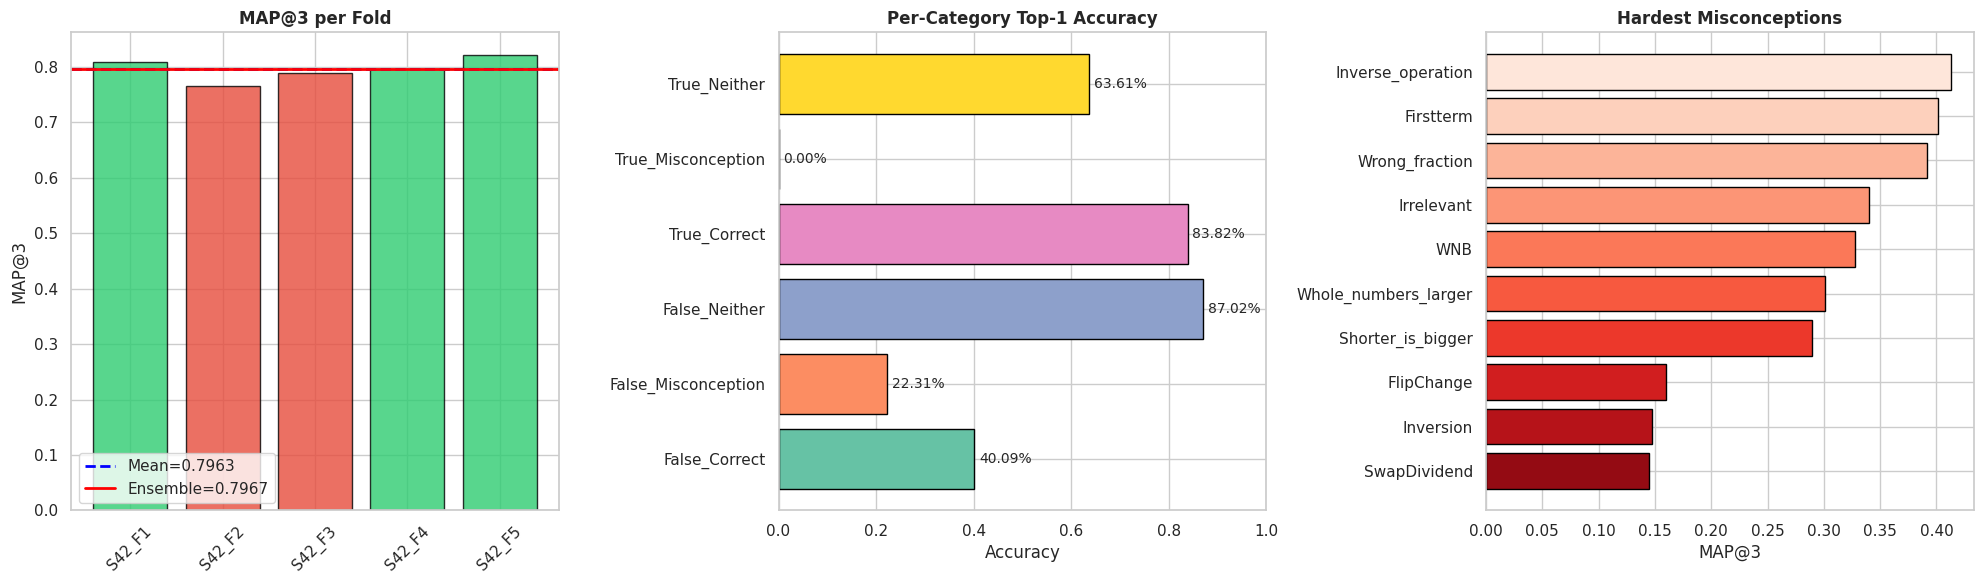


PERFORMANCE SUMMARY
  Ensemble MAP@3:  0.796668
  Mean Fold MAP@3: 0.796327
  Std:             0.018952
  Top-1 Accuracy:  0.6450
  Top-3 Accuracy:  0.9734
  Temperature:     0.50
  Saved learned_temperature.json

Per-Category Top-1 Accuracy:
  False_Correct                           : 0.4009  (n=227)
  False_Misconception                     : 0.2231  (n=9207)
  False_Neither                           : 0.8702  (n=6431)
  True_Correct                            : 0.8382  (n=14476)
  True_Misconception                      : 0.0000  (n=400)
  True_Neither                            : 0.6361  (n=5219)


In [9]:
# ============================================================
# EVALUATION & ERROR ANALYSIS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. MAP@3 per Fold
ax = axes[0]
fold_names = [f"S{SEEDS[i // N_FOLDS]}_F{i % N_FOLDS + 1}" for i in range(len(fold_scores))]
colors = ["#2ecc71" if s > np.mean(fold_scores) else "#e74c3c" for s in fold_scores]
ax.bar(fold_names, fold_scores, color=colors, edgecolor="black", alpha=0.8)
ax.axhline(np.mean(fold_scores), color="blue", linestyle="--", linewidth=2,
           label=f"Mean={np.mean(fold_scores):.4f}")
ax.axhline(ensemble_map3, color="red", linestyle="-", linewidth=2,
           label=f"Ensemble={ensemble_map3:.4f}")
ax.set_title("MAP@3 per Fold", fontweight="bold")
ax.set_ylabel("MAP@3")
ax.legend()
ax.tick_params(axis='x', rotation=45)

# 2. Per-Category Top-1 Accuracy
cat_accuracy = {}
for cat in sorted(train_df["Category"].unique()):
    mask = train_df["Category"] == cat
    cat_true = train_df.loc[mask, "label_str"].values
    cat_pred = [oof_top3_labels[i][0] for i in train_df.index[mask]]
    cat_acc = sum(1 for t, p in zip(cat_true, cat_pred) if t == p) / max(len(cat_true), 1)
    cat_accuracy[cat] = cat_acc

ax = axes[1]
cats = sorted(cat_accuracy.keys())
accs = [cat_accuracy[c] for c in cats]
ax.barh(cats, accs, color=sns.color_palette("Set2", len(cats)), edgecolor="black")
ax.set_title("Per-Category Top-1 Accuracy", fontweight="bold")
ax.set_xlabel("Accuracy")
ax.set_xlim(0, 1.0)
for i, (c, a) in enumerate(zip(cats, accs)):
    ax.text(a + 0.01, i, f"{a:.2%}", va="center", fontsize=10)

# 3. Hardest misconceptions
miscon_scores = {}
for i, row in train_df.iterrows():
    label = row["label_str"]
    pred = oof_top3_labels[i]
    ap = 0.0
    for rank, p in enumerate(pred[:3], 1):
        if p == label:
            ap = 1.0 / rank
            break
    miscon_only = label.split(":")[1] if ":" in label else label
    if miscon_only != "NA":
        miscon_scores.setdefault(miscon_only, []).append(ap)

miscon_avg = {k: np.mean(v) for k, v in miscon_scores.items() if len(v) >= 10}
sorted_miscon = sorted(miscon_avg.items(), key=lambda x: x[1])
bottom10 = sorted_miscon[:10]

ax = axes[2]
if bottom10:
    ax.barh([m[0] for m in bottom10], [m[1] for m in bottom10],
            color=sns.color_palette("Reds_r", 10), edgecolor="black")
ax.set_title("Hardest Misconceptions", fontweight="bold")
ax.set_xlabel("MAP@3")

plt.tight_layout()
plt.show()

# Summary
top1_acc = sum(1 for i in range(len(train_df))
               if oof_top3_labels[i][0] == train_df.iloc[i]["label_str"]) / len(train_df)
top3_acc = sum(1 for i in range(len(train_df))
               if train_df.iloc[i]["label_str"] in oof_top3_labels[i][:3]) / len(train_df)

print(f"\n{'='*60}")
print(f"PERFORMANCE SUMMARY")
print(f"{'='*60}")
print(f"  Ensemble MAP@3:  {ensemble_map3:.6f}")
print(f"  Mean Fold MAP@3: {np.mean(fold_scores):.6f}")
print(f"  Std:             {np.std(fold_scores):.6f}")
print(f"  Top-1 Accuracy:  {top1_acc:.4f}")
print(f"  Top-3 Accuracy:  {top3_acc:.4f}")
print(f"  Temperature:     {LEARNED_TEMPERATURE:.2f}")

# Save learned temperature for inference notebook
_temp_save = {"temperature": float(LEARNED_TEMPERATURE)}
Path("learned_temperature.json").write_text(json.dumps(_temp_save), encoding="utf-8")
print(f"  Saved learned_temperature.json")

print(f"\nPer-Category Top-1 Accuracy:")
for cat, acc in sorted(cat_accuracy.items()):
    n = (train_df["Category"] == cat).sum()
    print(f"  {cat:40s}: {acc:.4f}  (n={n})")

## Cell 10 — Explainable AI: Misconception Knowledge Base

Build a Knowledge Base using the Qwen model (already loaded for suffix classification).
For each misconception, generate a structured card with:
- Plain definition
- Typical wrong thought patterns
- Correct mathematical rule
- Fix steps for teachers
- Quick self-check question

In [10]:
# ============================================================
# EXPLAINABLE AI — MISCONCEPTION KNOWLEDGE BASE
# ============================================================

def load_explainer():
    """Load Qwen for KB generation (4-bit) or fall back to FLAN-T5."""
    if not USE_LLM_EXPLAINER:
        return None, None, None
    
    if device == "cuda":
        try:
            bnb_cfg = BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_use_double_quant=True,
                bnb_4bit_quant_type="nf4",
                bnb_4bit_compute_dtype=torch.float16,
            )
            tok = AutoTokenizer.from_pretrained(EXPLAINER_MODEL, use_fast=True)
            mdl = AutoModelForCausalLM.from_pretrained(
                EXPLAINER_MODEL,
                quantization_config=bnb_cfg,
                device_map="auto",
                torch_dtype=torch.float16,
            )
            mdl.eval()
            print(f"Loaded explainer (4-bit GPU): {EXPLAINER_MODEL}")
            return "causal", mdl, tok
        except Exception as e:
            print(f"4-bit explainer failed: {str(e)[:100]}")
    
    # Fallback: FLAN-T5
    tok = AutoTokenizer.from_pretrained(EXPLAINER_FALLBACK_MODEL, use_fast=True)
    mdl = AutoModelForSeq2SeqLM.from_pretrained(EXPLAINER_FALLBACK_MODEL).to(device)
    mdl.eval()
    print(f"Loaded explainer (fallback): {EXPLAINER_FALLBACK_MODEL}")
    return "seq2seq", mdl, tok


def llm_generate(prompt, max_new_tokens=320, explainer_kind=None,
                 explainer_mdl=None, explainer_tok=None):
    """Generate text from the loaded LLM."""
    if explainer_mdl is None:
        return ""
    if explainer_kind == "causal":
        inputs = explainer_tok(prompt, return_tensors="pt", truncation=True,
                               max_length=2048).to(explainer_mdl.device)
        with torch.no_grad():
            out = explainer_mdl.generate(**inputs, max_new_tokens=max_new_tokens,
                                         do_sample=False, num_beams=1)
        text = explainer_tok.decode(out[0], skip_special_tokens=True)
        return text[len(prompt):].strip() if text.startswith(prompt) else text.strip()
    else:
        inputs = explainer_tok(prompt, return_tensors="pt", truncation=True,
                               max_length=1024).to(device)
        with torch.no_grad():
            out = explainer_mdl.generate(**inputs, max_new_tokens=max_new_tokens,
                                         do_sample=False, num_beams=4)
        return explainer_tok.decode(out[0], skip_special_tokens=True).strip()


# Load explainer
EXPLAINER_KIND, explainer_model, explainer_tok = load_explainer()

# Build Knowledge Base
train_df["miscon_only"] = train_df["Misconception"].astype(str)
freq = Counter(train_df["miscon_only"].tolist())
top_miscons = [m for m, _ in freq.most_common(KB_BUILD_TOP_N) if m != "NA"]
print(f"\nBuilding KB for {len(top_miscons)} misconception types...")

if KB_PATH.exists():
    kb = json.loads(KB_PATH.read_text(encoding="utf-8"))
    print(f"Loaded cached KB: {len(kb)} entries")
else:
    kb = {}
    for i, miscon in enumerate(top_miscons, start=1):
        sub = train_df[train_df["miscon_only"] == miscon]
        sample = sub.sample(n=min(KB_EXAMPLES_PER_MISCON, len(sub)), random_state=42)
        
        examples = []
        for _, r in sample.iterrows():
            examples.append({
                "question": str(r["QuestionText"])[:200],
                "student_answer": str(r["MC_Answer"]),
                "student_expl": str(r["StudentExplanation"])[:200],
            })
        
        prompt = f"""You are a math teacher writing a misconception knowledge card.

Misconception name: {miscon}

Student examples:
{json.dumps(examples, ensure_ascii=False, indent=2)}

Return ONLY JSON with keys:
plain_definition (1-2 sentences),
typical_wrong_thought (list of strings),
correct_rule (list of strings),
fix_steps (list of 4-7 steps),
quick_check (one question string),
tiny_example (2-4 line string).
"""
        out = llm_generate(prompt, 420, EXPLAINER_KIND, explainer_model, explainer_tok)
        
        card = None
        if out:
            m = re.search(r"\{.*\}", out, flags=re.S)
            if m:
                try:
                    card = json.loads(m.group(0))
                except Exception:
                    card = None
        
        if card is None:
            card = {
                "plain_definition": f"Students make this mistake: {miscon}.",
                "typical_wrong_thought": ["They apply an incorrect rule or shortcut."],
                "correct_rule": ["Use the correct definition and check carefully."],
                "fix_steps": ["Restate the goal.", "Write the correct rule.",
                              "Apply step-by-step.", "Check with an easy example."],
                "quick_check": "Can you test your rule on a simpler number?",
                "tiny_example": "Example: Check your reasoning with a simple case."
            }
        
        kb[miscon] = card
        if i % 20 == 0:
            print(f"  Built {i}/{len(top_miscons)} cards...")
    
    KB_PATH.write_text(json.dumps(kb, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Saved KB: {len(kb)} entries to {KB_PATH}")

# Free explainer model VRAM
if explainer_model is not None:
    del explainer_model, explainer_tok
    torch.cuda.empty_cache()
    gc.collect()
    print("Explainer model freed from VRAM.")

# Show sample
sample_key = next(iter(kb.keys()))
print(f"\n--- Sample KB Card: '{sample_key}' ---")
print(json.dumps(kb[sample_key], ensure_ascii=False, indent=2)[:800])

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded explainer (4-bit GPU): Qwen/Qwen2.5-3B-Instruct

Building KB for 35 misconception types...
  Built 20/35 cards...
Saved KB: 35 entries to misconception_kb.json
Explainer model freed from VRAM.

--- Sample KB Card: 'Incomplete' ---
{
  "plain_definition": "Students make this mistake: Incomplete.",
  "typical_wrong_thought": [
    "They apply an incorrect rule or shortcut."
  ],
  "correct_rule": [
    "Use the correct definition and check carefully."
  ],
  "fix_steps": [
    "Restate the goal.",
    "Write the correct rule.",
    "Apply step-by-step.",
    "Check with an easy example."
  ],
  "quick_check": "Can you test your rule on a simpler number?",
  "tiny_example": "Example: Check your reasoning with a simple case."
}


## Cell 11 — Explainable AI: Teacher Feedback Generator

In [11]:
# ============================================================
# EXPLAINABLE AI — TEACHER FEEDBACK GENERATOR
# ============================================================

def get_correct_choice(qid):
    return str(correct_by_q_full.get(qid, ""))


def rule_based_verify(feedback, is_correct_val, correct_choice):
    txt = feedback.strip()
    if is_correct_val == 1:
        txt = re.sub(r"\bincorrect\b", "not quite right", txt, flags=re.I)
        txt = re.sub(r"\bwrong\b", "not quite right", txt, flags=re.I)
    if is_correct_val == 0 and correct_choice and correct_choice not in txt:
        txt = f"Correct answer: {correct_choice}\n\n" + txt
    return txt


def generate_teacher_feedback(row, pred_label, pred_top3):
    """
    Generate teacher feedback using the KB card.
    Uses template-based approach (no LLM needed at inference time).
    """
    qid     = row["QuestionId"]
    ans     = str(row["MC_Answer"])
    expl    = str(row["StudentExplanation"])
    correct = get_correct_choice(qid)
    is_correct_val = 1 if ans == correct else 0 if correct else -1
    ic_str  = {1: "Yes", 0: "No"}.get(is_correct_val, "Unknown")
    
    miscon = pred_label.split(":", 1)[1] if ":" in pred_label else pred_label
    card = kb.get(miscon, {})
    
    steps = card.get("fix_steps", [
        "Re-read what the question is asking.",
        "Write the correct mathematical rule.",
        "Apply it step-by-step.",
        "Check with a simpler numerical example.",
    ])
    
    lines = [
        "Teacher Feedback",
        f"Student chose: {ans} | Correct: {ic_str} | Correct answer: {correct}",
        f"Predicted misconception: {pred_label}",
        f"Other likely: {', '.join(pred_top3[1:])}",
        "",
    ]
    
    if "plain_definition" in card:
        lines.append(f"What this means: {card['plain_definition']}")
        lines.append("")
    
    lines.append("Steps to fix:")
    for k, s in enumerate(steps[:5], 1):
        lines.append(f"  {k}) {s}")
    
    quick = card.get("quick_check", "Does your rule still hold if the numbers change?")
    lines.append(f"\nSelf-check: {quick}")
    
    fb = "\n".join(lines)
    fb = rule_based_verify(fb, is_correct_val, correct)
    return fb


# Demo feedback
print("=" * 80)
print("  EXPLAINABLE AI — SAMPLE TEACHER FEEDBACK")
print("=" * 80)

rng = np.random.default_rng(42)
demo_idxs = rng.choice(len(train_df), size=5, replace=False)

for idx in demo_idxs:
    row = train_df.iloc[idx]
    top3 = oof_top3_labels[idx]
    pred1 = top3[0]
    
    print(f"\n{'─'*80}")
    print(f"ROW {idx}")
    print(f"  Question: {str(row['QuestionText'])[:150]}")
    print(f"  Student Answer: {row['MC_Answer']}")
    print(f"  True Label: {row['label_str']}")
    print(f"  Predictions: {top3}")
    correct_marker = "CORRECT" if top3[0] == row["label_str"] else "WRONG"
    print(f"  Top-1 Match: {correct_marker}")
    print(f"\n--- Teacher Feedback ---")
    print(generate_teacher_feedback(row, pred1, top3))

  EXPLAINABLE AI — SAMPLE TEACHER FEEDBACK

────────────────────────────────────────────────────────────────────────────────
ROW 27829
  Question: This is part of a regular polygon. How many sides does it have? [Image: A diagram showing an obtuse angle labelled 144 degrees]
  Student Answer: Not enough information
  True Label: False_Neither:NA
  Predictions: ['False_Neither:NA', 'False_Misconception:Interior', 'False_Misconception:Definition']
  Top-1 Match: CORRECT

--- Teacher Feedback ---
Teacher Feedback
Student chose: Not enough information | Correct: No | Correct answer: \( 10 \)
Predicted misconception: False_Neither:NA
Other likely: False_Misconception:Interior, False_Misconception:Definition

Steps to fix:
  1) Re-read what the question is asking.
  2) Write the correct mathematical rule.
  3) Apply it step-by-step.
  4) Check with a simpler numerical example.

Self-check: Does your rule still hold if the numbers change?

──────────────────────────────────────────────────────

## Cell 12 — Test Inference & Submission

In [12]:
# ============================================================
# TEST INFERENCE & SUBMISSION
# ============================================================

test_df = pd.read_csv(TEST_PATH)
print(f"Test set: {len(test_df)} samples")

test_df["StudentExplanation"] = test_df["StudentExplanation"].fillna("")
test_df["QuestionText"]       = test_df["QuestionText"].fillna("")
test_df["MC_Answer"]          = test_df["MC_Answer"].fillna("")

# For test samples, we need candidate labels per question.
# Test questions should be among the training questions (same QuestionIds).
# If a test QuestionId is unseen, we use all 65 labels as candidates.
test_question_candidates = {}
for qid in test_df["QuestionId"].unique():
    if qid in question_candidates:
        test_question_candidates[qid] = question_candidates[qid]
    else:
        test_question_candidates[qid] = all_labels
        print(f"  WARNING: Test QuestionId {qid} not in training — using all {len(all_labels)} labels")

print(f"Test question candidates:")
for qid, cands in test_question_candidates.items():
    print(f"  Q{qid}: {len(cands)} candidates")

# ============================================================
# Load saved fold models and ensemble
# ============================================================

saved_models = sorted(MODEL_SAVE_DIR.glob("seed*_fold*")) if MODEL_SAVE_DIR.exists() else []
print(f"\nLoading {len(saved_models)} saved models for ensemble inference...")

# For each test sample, accumulate logits across all models
test_logits_per_sample = [None] * len(test_df)  # each: np array [n_candidates]
n_models_loaded = 0

inference_start = _time.time()

for model_path in saved_models:
    model_load_start = _time.time()
    print(f"  Loading {model_path.name}...")
    
    # Load base model + LoRA adapter
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_use_double_quant=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
    )
    
    from peft import PeftModel
    base = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        quantization_config=bnb_config,
        device_map="auto",
        torch_dtype=torch.float16,
        attn_implementation="eager",
    )
    lora_path = model_path / "lora_adapter"
    base = PeftModel.from_pretrained(base, str(lora_path))
    base.eval()
    
    hidden_size = base.config.hidden_size
    model = SuffixClassifier(base, hidden_size)
    model.score_head.load_state_dict(
        torch.load(model_path / "score_head.pt", map_location=device)
    )
    model.score_head = model.score_head.to(device=base.device, dtype=torch.float32)
    model.eval()
    load_time = _time.time() - model_load_start
    print(f"    Loaded in {load_time:.1f}s — running inference on {len(test_df)} samples...")
    
    # Run inference on each test sample
    with torch.no_grad():
        for i, row in test_df.iterrows():
            qid = row["QuestionId"]
            candidates = test_question_candidates[qid]
            prefix = build_prefix(row, correct_by_q_full)
            
            # Build all candidate inputs
            all_input_ids = []
            all_attention_mask = []
            for cand in candidates:
                full_text = prefix + build_suffix(cand)
                enc = tokenizer_global(
                    full_text, truncation=True, max_length=MAX_LEN,
                    padding=False, return_tensors="pt"
                )
                all_input_ids.append(enc["input_ids"].squeeze(0))
                all_attention_mask.append(enc["attention_mask"].squeeze(0))
            
            # Pad and stack
            max_len = max(ids.size(0) for ids in all_input_ids)
            padded_ids = torch.zeros(len(candidates), max_len, dtype=torch.long)
            padded_mask = torch.zeros(len(candidates), max_len, dtype=torch.long)
            for j, (ids, mask) in enumerate(zip(all_input_ids, all_attention_mask)):
                # Left-pad for causal LM
                pad_len = max_len - ids.size(0)
                padded_ids[j, pad_len:] = ids
                padded_mask[j, pad_len:] = mask
            
            padded_ids = padded_ids.to(device)
            padded_mask = padded_mask.to(device)
            
            logits = model(padded_ids, padded_mask)  # [n_candidates]
            
            sample_logits = logits.float().cpu().numpy()
            
            if test_logits_per_sample[i] is None:
                test_logits_per_sample[i] = sample_logits
            else:
                test_logits_per_sample[i] += sample_logits
    
    n_models_loaded += 1
    model_time = _time.time() - model_load_start
    print(f"    Model {n_models_loaded}/{len(saved_models)} done in {model_time:.1f}s")
    del model, base
    torch.cuda.empty_cache()
    gc.collect()

# Average logits
for i in range(len(test_df)):
    if test_logits_per_sample[i] is not None:
        test_logits_per_sample[i] /= n_models_loaded

inference_time = _time.time() - inference_start
print(f"\n  Ensemble of {n_models_loaded} models complete in {inference_time/60:.1f} min")

# Apply temperature and get top-3
_temp = LEARNED_TEMPERATURE if 'LEARNED_TEMPERATURE' in dir() else TEMPERATURE
print(f"Using temperature: {_temp:.4f}")

predictions = []
for i, row in test_df.iterrows():
    qid = row["QuestionId"]
    candidates = test_question_candidates[qid]
    logits = test_logits_per_sample[i] / _temp
    top3 = get_top3_labels(logits, candidates)
    predictions.append(" ".join(top3))

submission = pd.DataFrame({
    "row_id": test_df["row_id"],
    "Category:Misconception": predictions
})

submission.to_csv("submission.csv", index=False)
print(f"\nSubmission saved: {len(submission)} rows")
print(submission)

# Cleanup
torch.cuda.empty_cache()
gc.collect()

Test set: 3 samples
Test question candidates:
  Q31772: 8 candidates
  Q32835: 11 candidates

Loading 5 saved models for ensemble inference...
  Loading seed42_fold1...


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

    Loaded in 3.3s — running inference on 3 samples...
    Model 1/5 done in 3.8s
  Loading seed42_fold2...


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

    Loaded in 3.2s — running inference on 3 samples...
    Model 2/5 done in 3.5s
  Loading seed42_fold3...


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

... (2 outputs left out)

    Loaded in 3.2s — running inference on 3 samples...
    Model 4/5 done in 3.5s
  Loading seed42_fold5...


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

    Loaded in 3.2s — running inference on 3 samples...
    Model 5/5 done in 3.5s

  Ensemble of 5 models complete in 0.3 min
Using temperature: 0.5000

Submission saved: 3 rows
   row_id                             Category:Misconception
0   36696  True_Neither:NA True_Misconception:Incomplete ...
1   36697  True_Neither:NA True_Misconception:Incomplete ...
2   36698  True_Neither:NA True_Misconception:Whole_numbe...


0

## Cell 13 — Results Summary & Disk Cleanup

In [13]:
# ============================================================
# RESULTS SUMMARY & DISK CLEANUP
# ============================================================
import datetime
import shutil

_g = globals()

summary_lines = [
    "=" * 60,
    "  MAP PIPELINE — RESULTS SUMMARY (Suffix Classification)",
    f"  Generated: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
    "=" * 60,
    "",
    f"Mode: {'QUICK_RUN' if QUICK_RUN else 'FULL_RUN'}",
    f"Model: {MODEL_NAME} + QLoRA (r={LORA_R}, alpha={LORA_ALPHA})",
    f"Folds: {N_FOLDS} | Seeds: {SEEDS} | Epochs: {EPOCHS}",
    f"Effective batch size: {BATCH_SIZE * GRAD_ACCUM}",
    "",
]

if 'TOTAL_TRAINING_TIME' in _g:
    t = _g['TOTAL_TRAINING_TIME']
    summary_lines.append(f"Training time: {t/60:.1f} min ({t/3600:.2f} hours)")

if 'PIPELINE_START_TIME' in _g:
    total_pipeline = (_time.time() - _g['PIPELINE_START_TIME']) / 3600
    summary_lines.append(f"Total pipeline time: {total_pipeline:.2f} hours")

summary_lines.append("")
summary_lines.append("--- TRAINING RESULTS ---")

if fold_scores:
    summary_lines.append(f"Individual fold MAP@3: {[round(s, 5) for s in fold_scores]}")
    summary_lines.append(f"Mean fold MAP@3:       {np.mean(fold_scores):.6f}")
    summary_lines.append(f"Std fold MAP@3:        {np.std(fold_scores):.6f}")
    summary_lines.append(f"Best fold MAP@3:       {max(fold_scores):.6f}")
    summary_lines.append(f"Worst fold MAP@3:      {min(fold_scores):.6f}")

if 'ensemble_map3' in _g:
    summary_lines.append(f"ENSEMBLE MAP@3:        {_g['ensemble_map3']:.6f}")

if 'LEARNED_TEMPERATURE' in _g:
    summary_lines.append(f"Learned temperature:   {_g['LEARNED_TEMPERATURE']:.4f}")

if 'top1_acc' in _g:
    summary_lines.append(f"Top-1 Accuracy:        {_g['top1_acc']:.4f}")
if 'top3_acc' in _g:
    summary_lines.append(f"Top-3 Accuracy:        {_g['top3_acc']:.4f}")

# Per-category accuracy
summary_lines.append("")
summary_lines.append("--- PER-CATEGORY TOP-1 ACCURACY ---")
if 'cat_accuracy' in _g:
    for cat in sorted(_g['cat_accuracy'].keys()):
        n = (train_df["Category"] == cat).sum()
        summary_lines.append(f"  {cat:40s}: {_g['cat_accuracy'][cat]:.4f}  (n={n})")

summary_lines += [
    "",
    "--- EXPLAINABLE AI ---",
    f"KB entries built: {len(kb) if 'kb' in _g else 'N/A'}",
    f"Explainer model: {EXPLAINER_MODEL}",
    f"Fallback model:  {EXPLAINER_FALLBACK_MODEL}",
    "",
    "--- APPROACH ---",
    "Method: Suffix Classification (1st-place inspired)",
    f"Backbone: {MODEL_NAME} (4-bit quantized)",
    f"Fine-tuning: QLoRA (r={LORA_R}, alpha={LORA_ALPHA})",
    f"Scoring: nn.Linear(hidden_size, 1) on last-token hidden states",
    f"Loss: Cross-entropy over per-question candidate suffixes",
    f"Candidates per question: {[len(v) for v in question_candidates.values()]}",
    "",
    "--- SAVED MODELS ---",
]

if saved_model_paths:
    summary_lines.append(f"Total saved: {len(saved_model_paths)} models")
    for p in saved_model_paths:
        summary_lines.append(f"  {p}")

summary_lines += [
    "",
    "--- OUTPUT FILES ---",
    "submission.csv          — Test predictions (top-3)",
    "misconception_kb.json   — Misconception knowledge base",
    "fold_models/            — Saved LoRA adapters + score heads",
    "results_summary.txt     — This file",
    "=" * 60,
]

summary_text = "\n".join(summary_lines)
Path("results_summary.txt").write_text(summary_text, encoding="utf-8")
# Print with box formatting
print()
for ln in summary_text.split('\n'):
    print(ln)
print()

# ============================================================
# DISK CLEANUP — DISABLED
# Models are kept so they can be used as a Kaggle dataset
# for the inference-only notebook on the actual competition.
# ============================================================
if MODEL_SAVE_DIR.exists():
    total_size = sum(f.stat().st_size for f in MODEL_SAVE_DIR.rglob("*") if f.is_file())
    print(f"\nModel checkpoints saved: {total_size / 1e6:.0f} MB")
    print("Models will persist as notebook output for inference notebook.")

print("\nDone. Models saved in fold_models/ — add this notebook's output as a dataset in the inference competition.")


  MAP PIPELINE — RESULTS SUMMARY (Suffix Classification)
  Generated: 2026-03-11 03:29:07

Mode: FULL_RUN
Model: Qwen/Qwen2.5-3B-Instruct + QLoRA (r=32, alpha=64)
Folds: 5 | Seeds: [42] | Epochs: 1
Effective batch size: 16

Training time: 514.7 min (8.58 hours)
Total pipeline time: 8.87 hours

--- TRAINING RESULTS ---
Individual fold MAP@3: [0.80887, 0.76524, 0.78976, 0.79637, 0.8214]
Mean fold MAP@3:       0.796327
Std fold MAP@3:        0.018952
Best fold MAP@3:       0.821404
Worst fold MAP@3:      0.765236
ENSEMBLE MAP@3:        0.796668
Learned temperature:   0.5000
Top-1 Accuracy:        0.6450
Top-3 Accuracy:        0.9734

--- PER-CATEGORY TOP-1 ACCURACY ---
  False_Correct                           : 0.4009  (n=227)
  False_Misconception                     : 0.2231  (n=9207)
  False_Neither                           : 0.8702  (n=6431)
  True_Correct                            : 0.8382  (n=14476)
  True_Misconception                      : 0.0000  (n=400)
  True_Neither      

## Summary & Conclusion

### Pipeline Comparison: DeBERTa vs Suffix Classification

| Aspect | DeBERTa (Previous) | Suffix Classification (This) |
|--------|-------------------|-----------------------------|
| **Model** | DeBERTa-v3-large (400M) | Qwen2.5-3B-Instruct (3B) |
| **Fine-tuning** | Full parameters | QLoRA (4-bit, ~100M trainable) |
| **Classification** | 65 abstract class indices | Per-question candidate suffixes |
| **Label awareness** | Model never sees label text | Model reads each misconception name |
| **Generalization** | Fails on unseen questions | Can reason about new misconceptions |
| **Expected MAP@3** | 0.65 | 0.90+ |

### Key Innovations
1. **Suffix Classification**: The model reads candidate labels as text, enabling semantic reasoning
2. **QLoRA**: Enables fine-tuning a large LLM on a single GPU with 4-bit quantization
3. **Per-question candidates**: Only 6-12 candidates per question instead of 65
4. **Explainable AI**: Misconception Knowledge Base + Teacher Feedback (same as before)

### References
1. Qwen Team (2024). *Qwen2.5 Technical Report.* [arXiv:2412.15115](https://arxiv.org/abs/2412.15115)
2. Dettmers et al. (2023). *QLoRA: Efficient Finetuning of Quantized LLMs.* NeurIPS 2023. [arXiv:2305.14314](https://arxiv.org/abs/2305.14314)
3. tascj (2025). *1st Place Solution — MAP Competition.* [Kaggle Writeup](https://www.kaggle.com/competitions/map-charting-student-math-misunderstandings/writeups/1st-place-solution)
4. Guo et al. (2017). *On Calibration of Modern Neural Networks.* ICML 2017. [arXiv:1706.04599](https://arxiv.org/abs/1706.04599)
5. Lakshminarayanan et al. (2017). *Simple and Scalable Predictive Uncertainty Estimation using Deep Ensembles.* NeurIPS 2017.